<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER
        </h2>
        <h1 style="margin-top: -10px;">MARCO DE TRABAJO DE RECOMENDACIÓN DE TALENTO PARA LA FORMACIÓN DE EQUIPOS EN PROYECTOS DE INGENIERÍA DEL SOFTWARE</h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Profesores
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">
                        Aurora Vizcaíno Barcelo
                    </span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">
                        Julio Alberto López Gómez
                    </span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 2: Preparación para minería de reglas)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        Tras realizar la limpieza y el EDA de la encuesta de soft skills (2019), el objetivo de esta segunda libreta será <strong>transformar el dataset limpio en una matriz transaccional binaria [0, 1]</strong>, formato necesario para aplicar algoritmos de reglas de asociación (Apriori, Eclat, FP-Growth).
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Binarización de variables multi-valor:</strong> Convertiremos <code>WorkChallenge</code> y <code>JobFactors</code> (texto separado por <code>;</code>) en columnas independientes de ceros y unos, usando <code>codificar_multilabel</code>.</li>
        <li><strong>Discretización de variables continuas:</strong> Convertiremos <code>WorkWeekHrs</code> y <code>CodeRevHrs</code> en tramos categóricos, ya que las reglas de asociación no operan sobre valores numéricos continuos.</li>
        <li><strong>One-Hot Encoding del resto de categóricas:</strong> Incluyendo las variables ya derivadas en el EDA (<code>WorkRemote_Bucket</code>, <code>Neuroticismo_Nivel</code>, <code>Amabilidad_Nivel</code>, <code>Apertura_Nivel</code>).</li>
        <li><strong>Tratamiento de "Not Applicable"/"Not Provided":</strong> Decisión explícita sobre cómo tratar estas categorías para evitar reglas triviales de soporte artificialmente alto.</li>
    </ul>
</div>
<br/>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 2.1. Configuración y carga de datos limpios

Primero de todo, importamos las librerías para tratar los datos (`pandas`, `numpy`) y las herramientas de escalado de `scikit-learn`. Después, cargamos el dataset resultante de la libreta anterior, el cual ya ha sido purgado de valores duplicados y nulos estructurales.

In [1]:
import os
import sys
import warnings

sys.path.append(os.path.abspath(os.path.join('../..')))

from src.soft_skills import config
from src.soft_skills import utils_soft

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
from sklearn import set_config
from IPython.display import display

random_state = seed = 42
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

In [2]:
df_feature_engineering_soft = pd.read_csv(config.PROCESSED_EDA_PATH, index_col='CandidateId', low_memory=False)

print(f"Dimensiones dataset: {df_feature_engineering_soft.shape}")
display(df_feature_engineering_soft.head(5))

Dimensiones dataset: (88778, 37)


,Hobbyist,OpenSourcer,Employment,CareerSat,JobSat,MgrIdiot,MgrWant,JobSeek,LastHireDate,JobFactors,...,WorkWeekHrs_is_missing,CodeRevHrs_is_missing,WorkRemote_Pct,WorkRemote_Bucket,Neuroticismo_Score,Amabilidad_Score,Apertura_Score,Neuroticismo_Nivel,Amabilidad_Nivel,Apertura_Nivel
CandidateId,,,,,,,,,,,,,,,,,,,,,
1,Yes,Never,"Not employed, and not looking for work",Not Applicable,Not Applicable,Not Applicable,Not Applicable,Not Provided,Not Provided,Not Applicable,...,1,1,NaN,Desconocido (Sin datos),NaN,0.660000,0.666667,Desconocido,Medio,Medio
2,No,Less than once per year,"Not employed, but looking for work",Not Applicable,Not Applicable,Not Applicable,Not Applicable,I am actively looking for a job,I've never had a job,Financial performance or funding status of the...,...,1,1,NaN,Desconocido (Sin datos),NaN,0.660000,0.444444,Desconocido,Medio,Medio
3,Yes,Never,Employed full-time,Slightly satisfied,Slightly satisfied,Not at all confident,Not sure,"I’m not actively looking, but I am open to new...",1-2 years ago,"Languages, frameworks, and other technologies ...",...,0,1,0.0,Presencial / Bajo remoto (<30%),0.152778,0.220000,0.666667,Medio,Bajo,Medio
4,No,Never,Employed full-time,Very satisfied,Slightly satisfied,Very confident,Not sure,I am not interested in new job opportunities,Less than a year ago,"Languages, frameworks, and other technologies ...",...,0,1,0.0,Presencial / Bajo remoto (<30%),0.437500,0.553333,0.333333,Alto,Bajo,Bajo
5,Yes,Once a month or more often,Employed full-time,Very dissatisfied,Slightly dissatisfied,Somewhat confident,No,I am not interested in new job opportunities,Less than a year ago,"Industry that I'd be working in;Languages, fra...",...,0,1,10.0,Presencial / Bajo remoto (<30%),0.673611,0.580000,1.000000,Alto,Medio,Alto


### 2.2. Análisis de Datos

Antes de transformar los datos, revisamos los datos utilizando `.info()` y viendo cuantos valores nulos hay. Esto nos permite identificar rápidamente el porcentaje de información faltante en cada variable y separar lógicamente nuestras columnas en categóricas, continuas o binarias. Esta "radiografía" es el paso previo esencial para diseñar un pipeline de limpieza preciso.

In [3]:
df_feature_engineering_soft.info()

<class 'pandas.DataFrame'>
Index: 88778 entries, 1 to 88863
Data columns (total 37 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Hobbyist                88778 non-null  str    
 1   OpenSourcer             88778 non-null  str    
 2   Employment              88778 non-null  str    
 3   CareerSat               88778 non-null  str    
 4   JobSat                  88778 non-null  str    
 5   MgrIdiot                88778 non-null  str    
 6   MgrWant                 88778 non-null  str    
 7   JobSeek                 88778 non-null  str    
 8   LastHireDate            88778 non-null  str    
 9   JobFactors              88778 non-null  str    
 10  ResumeUpdate            88778 non-null  str    
 11  WorkWeekHrs             64503 non-null  float64
 12  WorkPlan                88778 non-null  str    
 13  WorkChallenge           88778 non-null  str    
 14  WorkRemote              88778 non-null  str    
 15  W

### 2.3. Limpieza estructural e imputación

Antes de comenzar a transformar los datos, necesitamos ver con más detalle la estructura del dataset. En esta celda vemos los **tipos de datos**, cuántas variables tenemos de tipo numérico, categórico (objeto) o booleano para definir nuestra estrategia de transformación.
Después vemos el **porcentaje de nulos** exacto por columna.

Con todo esto, nos es más fácil identificar qué variables superan un umbral crítico de nulos, algo muy importante para poder diseñar un pipeline de limpieza seguro y evitando ruido innecesario.

In [4]:
print("\nTipos de datos:")
display(df_feature_engineering_soft.dtypes.value_counts())

print("\nPorcentaje de nulos por columna (top 30):")
null_pct = (df_feature_engineering_soft.isna().mean() * 100).sort_values(ascending=False)
display(null_pct.head(30).to_frame("null_pct"))


Tipos de datos:


str        29
float64     6
int64       2
Name: count, dtype: int64


Porcentaje de nulos por columna (top 30):


,null_pct
CodeRevHrs,43.916286
WorkWeekHrs,27.343486
WorkRemote_Pct,24.971277
Neuroticismo_Score,17.944761
Amabilidad_Score,2.989479
JobSat,0.000000
CareerSat,0.000000
Employment,0.000000
OpenSourcer,0.000000
Hobbyist,0.000000


### 2.4 Clasificación automática de variables

Antes de transformar los datos, necesitamos saber con qué tipo de variable estamos tratando en cada columna, ya que cada una requiere un tratamiento distinto para llegar al formato transaccional binario que necesitan las reglas de asociación.

En esta celda iteramos sobre las columnas para clasificarlas automáticamente en tres tipos:
1. **Variables Categóricas (`object`, `category`):** Incluye tanto categóricas simples (`WorkPlan`, `MgrIdiot`...) como las de texto multi-valor (`WorkChallenge`, `JobFactors`), que requerirán *parsing* y binarización con `codificar_multilabel`.
2. **Variables Binarias:** Aquellas que ya son puramente `[0, 1]`. No requieren transformación adicional, ya están en formato de ítem transaccional.
3. **Variables Continuas:** Valores numéricos con mayor rango (`WorkWeekHrs`, `CodeRevHrs`), que necesitarán discretización en bins antes de poder usarse como ítems.

In [5]:
object_cols = df_feature_engineering_soft.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_all = df_feature_engineering_soft.select_dtypes(include=[np.number, "bool"]).columns.tolist()

binary_cols = []
continuous_cols = []

for c in numeric_all:
    vals = pd.Series(df_feature_engineering_soft[c].dropna().unique())
    if len(vals) <= 2 and set(vals.tolist()).issubset({0, 1, True, False}):
        binary_cols.append(c)
    else:
        continuous_cols.append(c)

categorical_cols = object_cols.copy()

print("Variables continuas:", len(continuous_cols))
display(continuous_cols)

print("Variables binarias:", len(binary_cols))
display(binary_cols)

print("Variables categóricas:", len(categorical_cols))
display(categorical_cols)

Variables continuas: 6


['WorkWeekHrs',
 'CodeRevHrs',
 'WorkRemote_Pct',
 'Neuroticismo_Score',
 'Amabilidad_Score',
 'Apertura_Score']

Variables binarias: 2


['WorkWeekHrs_is_missing', 'CodeRevHrs_is_missing']

Variables categóricas: 29


['Hobbyist',
 'OpenSourcer',
 'Employment',
 'CareerSat',
 'JobSat',
 'MgrIdiot',
 'MgrWant',
 'JobSeek',
 'LastHireDate',
 'JobFactors',
 'ResumeUpdate',
 'WorkPlan',
 'WorkChallenge',
 'WorkRemote',
 'WorkLoc',
 'ImpSyn',
 'CodeRev',
 'PurchaseHow',
 'PurchaseWhat',
 'BetterLife',
 'SocialMedia',
 'Extraversion',
 'SOVisitTo',
 'SOPartFreq',
 'WelcomeChange',
 'WorkRemote_Bucket',
 'Neuroticismo_Nivel',
 'Amabilidad_Nivel',
 'Apertura_Nivel']

### 2.5 Validación visual de la matriz (post-limpieza)

Ahora realizamos una comprobación visual definitiva sobre las variables numéricas utilizando `missingno`. 

Con este gráfico de matriz podemos ver de un solo vistazo que la integridad estructural del dataset es sólida y densa, lo que nos permite demostrar que hemos eliminado los valores perdidos, el requisito indispensable para garantizar que las transformaciones matemáticas complejas de las siguientes fases no generarán errores ni ítems corruptos en la matriz transaccional binaria que alimentará los algoritmos de reglas de asociación de las libretas posteriores

<Figure size 1000x500 with 0 Axes>

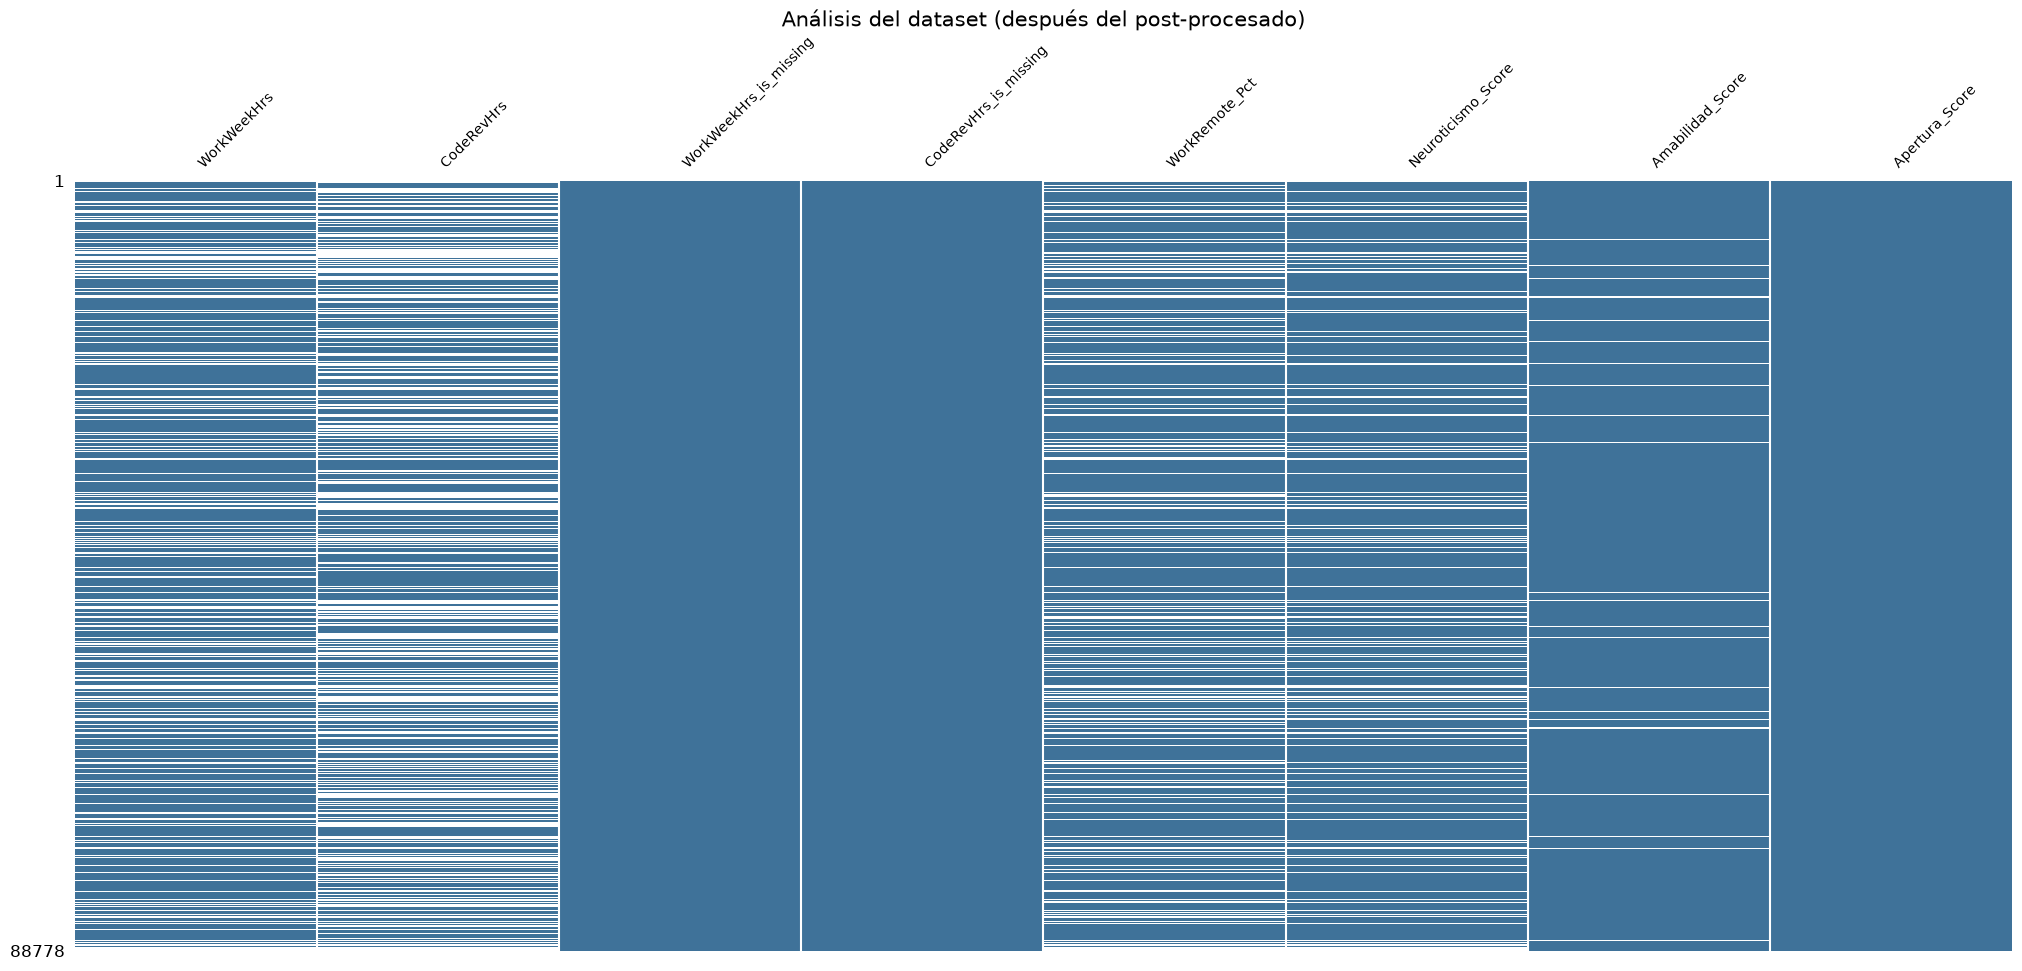

In [6]:
df_numericas = df_feature_engineering_soft.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 5))
msno.matrix(df_numericas, sparkline=False, fontsize=10, color=(0.25, 0.45, 0.6))
plt.title("Análisis del dataset (después del post-procesado)", fontsize=15)
plt.show()

### 2.6 Discretización de variables continuas

Como las reglas de asociación no pueden hacer cálculos con valores numéricos continuos, debemos modificar las variables `WorkWeekHrs` y `CodeRevHrs` a categóricas y discretizamos por intervalos.

Los cortes de `WorkWeekHrs` (`<35h`, `35-45h`, `45-55h`, `>55h`) no se eligen de forma arbitraria, si no que estos coinciden con la clasificación empleada por la Organización Mundial de la Salud y la Organización Internacional del Trabajo en su estudio conjunto de 2021 sobre los riesgos de la sobrecarga laboral, que establece 35-40h como jornada estándar de referencia y considera 55h o más semanales como el umbral asociado a problemas mentales y de salud muy serios. Como para este trabajo queremos contrastar estos patrones de riesgo, alineamos los tramos con el umbral que estas organizaciones establecen para aportar una base más sólida.

Por otra parte, con `CodeRevHrs` (`0h`, `0-2h`, `2-5h`, `>5h`) no tenemos un estándar reconocido, por lo que estos intervalos se eligen de forma equitativa y arbitraria.

Para ambos casos los valores nulos no serán asignados a ningún intervalo, estos se capturarán en `WorkWeekHrs_is_missing`/`CodeRevHrs_is_missing` y asignarles un intervalo aparte duplicaría estos valores.

In [7]:
def bin_workweek(horas):
    if pd.isna(horas): horassemana = np.nan
    elif horas < 35: horassemana = '<35h'
    elif horas <= 45: horassemana = '35-45h'
    elif horas <= 55: horassemana = '45-55h'
    else: horassemana = '>55h'
    return horassemana

def bin_coderev(horas):
    if pd.isna(horas): revcode = np.nan
    elif horas == 0: revcode = '0h (No revisa nada de código)'
    elif horas <= 2: revcode = '0-2h'
    elif horas <= 5: revcode = '2-5h'
    else: revcode = '>5h'
    return revcode

df_feature_engineering_soft['WorkWeekHrs_Bin'] = df_feature_engineering_soft['WorkWeekHrs'].apply(bin_workweek)
df_feature_engineering_soft['CodeRevHrs_Bin'] = df_feature_engineering_soft['CodeRevHrs'].apply(bin_coderev)

display(df_feature_engineering_soft['WorkWeekHrs_Bin'].value_counts(dropna=False))
display(df_feature_engineering_soft['CodeRevHrs_Bin'].value_counts(dropna=False))

WorkWeekHrs_Bin
35-45h    48393
NaN       24275
45-55h     6661
<35h       6336
>55h       3113
Name: count, dtype: int64

CodeRevHrs_Bin
NaN                              38988
2-5h                             21574
0-2h                             15488
>5h                              12515
0h (No revisa nada de código)      213
Name: count, dtype: int64

### 2.7 Binarización de variables multi-valor (`WorkChallenge`, `JobFactors`)

Estas dos variables son de elección múltiple, con varias respuestas separadas por `;`. Ante esta situación, vamos a aplicar `codificar_multilabel`, adaptada de la usada en hard skills, que convierte cada valor único en su propia columna binaria. A diferencia de las tecnologías en hard skills (decenas de valores posibles), aquí solo hay entre 7 y 10 categorías por columna, así que `top_n` actúa más como límite de seguridad que como filtro

In [8]:
for col in ['WorkChallenge', 'JobFactors']:
    df_feature_engineering_soft = utils_soft.codificar_multilabel(df_feature_engineering_soft, col, top_n=15)

print(f"Dimensiones tras binarizar WorkChallenge/JobFactors: {df_feature_engineering_soft.shape}")

Dimensiones tras binarizar WorkChallenge/JobFactors: (88778, 58)


### 2.8 One-Hot Encoding del resto de categóricas y limpieza de ítems triviales

A las variables categóricas simples les vamos aplicar One-Hot. Por lo tanto, vamos a excluir WorkRemote` (redundante con `WorkRemote_Bucket`, ya derivada de ella) y las variables `_Score`/`_Pct` continuas (reservadas para la fase de distancias del matching, no para esta matriz).

Después de tener las columnas binarias, vamos a eliminar aquellas que no tienen datos (`Not Applicable`/`Not Provided`), ya que no son respuestas reales y, de conservarse, introducirían ruido artificial en la posterior extracción de reglas

In [9]:
cols_exclusion_onehot = ['WorkRemote', 'WorkRemote_Pct', 'Neuroticismo_Score', 'Amabilidad_Score', 'Apertura_Score']
cols_categoricas_finales = [c for c in categorical_cols if c not in cols_exclusion_onehot + ['WorkChallenge', 'JobFactors']]

df_matriz = pd.get_dummies(df_feature_engineering_soft, columns=cols_categoricas_finales, dtype=int)
cols_triviales = [c for c in df_matriz.columns if c.endswith('_Not Applicable') or c.endswith('_Not Provided')]
df_matriz = df_matriz.drop(columns=cols_triviales)
print(f"Columnas triviales: {len(cols_triviales)}")

df_matriz = df_matriz.drop(columns=['WorkWeekHrs', 'CodeRevHrs', 'WorkRemote'] + [c for c in ['Neuroticismo_Score', 'Amabilidad_Score', 'Apertura_Score', 'WorkRemote_Pct'] if c in df_matriz.columns])
df_matriz = pd.get_dummies(df_matriz, columns=['WorkWeekHrs_Bin', 'CodeRevHrs_Bin'], dtype=int, dummy_na=False)

print(f"Dimensiones finales de la matriz : {df_matriz.shape}")
display(df_matriz.head(5))

Columnas triviales: 22
Dimensiones finales de la matriz : (88778, 205)


,WorkWeekHrs_is_missing,CodeRevHrs_is_missing,WorkChallenge_Distracting work environment,WorkChallenge_Meetings,WorkChallenge_Being tasked with non-development work,WorkChallenge_Not enough people for the workload,WorkChallenge_Lack of support from management,WorkChallenge_Inadequate access to necessary tools,WorkChallenge_Toxic work environment,WorkChallenge_Time spent commuting,...,Apertura_Nivel_Bajo,Apertura_Nivel_Medio,WorkWeekHrs_Bin_35-45h,WorkWeekHrs_Bin_45-55h,WorkWeekHrs_Bin_<35h,WorkWeekHrs_Bin_>55h,CodeRevHrs_Bin_0-2h,CodeRevHrs_Bin_0h (No revisa nada de código),CodeRevHrs_Bin_2-5h,CodeRevHrs_Bin_>5h
CandidateId,,,,,,,,,,,,,,,,,,,,,
1,1,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,0,1,1,0,0,0,1,1,0,0,...,0,1,1,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0
5,0,1,0,0,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0


### 2.9 Exportación de la matriz transaccional

Después de aplicar las transformaciones necesarias, exportamos la matriz para así poder continuar en las siguientes libretas con la minería de reglas de asociación y su contraste contra el conocimiento experto.

In [10]:
df_matriz.to_csv(config.MATRIZ_TRANSACCIONAL_PATH, index=True, index_label='CandidateId')
print(f"Matriz guardada en: {config.MATRIZ_TRANSACCIONAL_PATH}")
print(f"Dimensiones finales: {df_matriz.shape}")

Matriz guardada en: /home/miguel-angel/Escritorio/TFM/data/processed/soft_skills/matriz_transaccional_soft.csv
Dimensiones finales: (88778, 205)
